# Week 1 - Python Data Analysis: Mutual Fund Analytics

**Task:** load the CSV datasets, clean them, calculate KPIs and generate visualizations.

**Dataset:** the 10 Capstone CSVs (fund master, NAV history, AUM, SIP inflows, category inflows, folio counts, scheme performance, investor transactions, portfolio holdings, benchmark indices).

**Sections**
1. Setup and load data
2. Data cleaning (whitespace, naming, dates, duplicates, missing values)
3. Data validation checks
4. Outlier detection
5. Enrich transactions with fund details
6. KPIs
7. Visualizations and trend analysis
8. Basic statistics, correlation and regression
9. Key insights
10. Save cleaned datasets

In [5]:
%pip install pandas numpy matplotlib seaborn scipy

Note: you may need to restart the kernel to use updated packages.


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy import stats
import warnings
warnings.filterwarnings("ignore")

In [8]:
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:,.2f}".format)

In [9]:
def find_raw_dir():
    # Works from notebooks/ (CSVs in ../data/raw), from the project root, or next to the CSVs
    for cand in (Path("../data/raw"), Path("data/raw"), Path(".")):
        if cand.exists() and list(cand.glob("*fund_master*.csv")):
            return cand
    raise FileNotFoundError(
        "CSV files not found. Keep this notebook in notebooks/ (CSVs in ../data/raw) "
        "or put it in the same folder as the CSVs."
    )


RAW_DIR = find_raw_dir()
OUT_DIR = RAW_DIR.parent / "processed" if RAW_DIR.name == "raw" else Path("processed")
OUT_DIR.mkdir(parents=True, exist_ok=True)
print("Reading from :", RAW_DIR.resolve())
print("Saving to    :", OUT_DIR.resolve())

Reading from : C:\Users\Sakshi Mane
Saving to    : C:\Users\Sakshi Mane\processed


In [11]:
KEYS = {
    "df1": "01_fund_master",
    "df2": "02_nav_history",
    "df3": "03_aum_by_fund_house",
    "df4": "04_monthly_sip_inflows",
    "df5": "05_category_inflows",
    "df6": "06_industry_folio_count",
    "df7": "07_scheme_performance",
    "df8": "08_investor_transactions",
    "df9": "09_portfolio_holdings",
    "df10": "10_benchmark_indices",
}


def load(key):
    matches = sorted(RAW_DIR.glob(f"*{key}*.csv"))
    if not matches:
        raise FileNotFoundError(f"No CSV found for {key} in {RAW_DIR.resolve()}")
    return pd.read_csv(matches[0])


raw = {name: load(key) for name, key in KEYS.items()}
for name, df in raw.items():
    print(f"{name:<6} {df.shape[0]:>8,} rows x {df.shape[1]:>2} cols")

data = {name: df.copy() for name, df in raw.items()}  # working copies, raw stays untouched

df1          40 rows x 15 cols
df2      46,000 rows x  3 cols
df3          90 rows x  5 cols
df4          48 rows x  6 cols
df5         144 rows x  3 cols
df6          21 rows x  6 cols
df7          40 rows x 19 cols
df8      32,778 rows x 13 cols
df9         322 rows x  8 cols
df10      8,050 rows x  3 cols


**Data Cleaning**

In [91]:
cleaning_log = []


def note(dataset, action, count):
    cleaning_log.append({"dataset": dataset, "action": action, "affected": int(count)})


def text_cols(df):
    return [
        c for c in df.columns
        if not pd.api.types.is_numeric_dtype(df[c]) and not pd.api.types.is_datetime64_any_dtype(df[c])
    ]

In [92]:
for name, df in data.items():
    for c in text_cols(df):
        s = df[c]
        changed = int((s.notna() & (s.astype(str) != s.astype(str).str.strip())).sum())
        if changed:
            df[c] = s.str.strip()
            note(name, f"stripped whitespace in '{c}'", changed)
print("Whitespace fixes:", [e for e in cleaning_log if "whitespace" in e["action"]] or "none needed")

Whitespace fixes: none needed


In [93]:
for name in ("df1", "df3", "df7"):
    df = data[name]
    if "fund_house" in df.columns:
        before = df["fund_house"].copy()
        df["fund_house"] = df["fund_house"].str.replace(r"\s+MF$", " Mutual Fund", regex=True)
        note(name, "standardised fund_house names ('MF' -> 'Mutual Fund')", (before != df["fund_house"]).sum())

print(sorted(data["df1"]["fund_house"].unique()))

['Aditya Birla Sun Life Mutual Fund', 'Axis Mutual Fund', 'DSP Mutual Fund', 'HDFC Mutual Fund', 'ICICI Prudential Mutual Fund', 'Kotak Mahindra Mutual Fund', 'Mirae Asset Mutual Fund', 'Nippon India Mutual Fund', 'SBI Mutual Fund', 'UTI Mutual Fund']


In [94]:
DATE_COLS = {
    "df1": ["launch_date"],
    "df2": ["date"],
    "df3": ["date"],
    "df8": ["transaction_date"],
    "df9": ["portfolio_date"],
    "df10": ["date"],
}
MONTH_COLS = {"df4": "month", "df5": "month", "df6": "month"}  # format YYYY-MM

for name, cols in DATE_COLS.items():
    for c in cols:
        parsed = pd.to_datetime(data[name][c], errors="coerce")
        bad = int(parsed.isna().sum() - data[name][c].isna().sum())
        data[name][c] = parsed
        note(name, f"converted '{c}' to datetime (unparseable: {bad})", len(parsed))

for name, c in MONTH_COLS.items():
    parsed = pd.to_datetime(data[name][c], format="%Y-%m", errors="coerce")
    bad = int(parsed.isna().sum() - data[name][c].isna().sum())
    data[name][c] = parsed
    note(name, f"converted '{c}' (YYYY-MM) to datetime (unparseable: {bad})", len(parsed))

pd.DataFrame(
    {name: {c: str(df[c].dtype) for c in (DATE_COLS.get(name, []) + ([MONTH_COLS[name]] if name in MONTH_COLS else []))}
     for name, df in data.items() if name in DATE_COLS or name in MONTH_COLS}
).T

,launch_date,date,month,transaction_date,portfolio_date
df1,datetime64[ns],NaN,NaN,NaN,NaN
df2,NaN,datetime64[ns],NaN,NaN,NaN
df3,NaN,datetime64[ns],NaN,NaN,NaN
df4,NaN,NaN,datetime64[ns],NaN,NaN
df5,NaN,NaN,datetime64[ns],NaN,NaN
df6,NaN,NaN,datetime64[ns],NaN,NaN
df8,NaN,NaN,NaN,datetime64[ns],NaN
df9,NaN,NaN,NaN,NaN,datetime64[ns]
df10,NaN,datetime64[ns],NaN,NaN,NaN


In [20]:
print(data.keys())

dict_keys(['df1', 'df2', 'df3', 'df4', 'df5', 'df6', 'df7', 'df8', 'df9', 'df10'])


In [95]:
for name, df in list(data.items()):
    dups = int(df.duplicated().sum())
    if dups:
        data[name] = df.drop_duplicates().reset_index(drop=True)
    note(name, "removed duplicate rows", dups)

print({n: e["affected"] for e in cleaning_log if e["action"] == "removed duplicate rows" for n in [e["dataset"]]})

{'df1': 0, 'df2': 0, 'df3': 0, 'df4': 0, 'df5': 0, 'df6': 0, 'df7': 0, 'df8': 0, 'df9': 0, 'df10': 0}


In [96]:
missing = pd.concat({n: df.isna().sum() for n, df in data.items()}).rename("missing").reset_index()
missing.columns = ["dataset", "column", "missing"]
missing = missing[missing["missing"] > 0]
missing if len(missing) else print("No missing values left.")

,dataset,column,missing
28,df4,yoy_growth_pct,12


In [97]:
df1, df2, df8,df9 = data["df1"], data["df2"], data["df8"], data["df9"]
checks = []


def check(name, passed, detail=""):
    checks.append({"check": name, "result": "PASS" if passed else "FAIL", "detail": detail})


check("NAV values are all positive", (df2["nav"] > 0).all(), f"min NAV = {df2['nav'].min():.4f}")
check("Transaction amounts are all positive", (df8["amount_inr"] > 0).all(), f"min amount = {df8['amount_inr'].min():,}")
check("fund_master amfi_code is unique", df1["amfi_code"].is_unique)
check(
    "Every fund_master code exists in nav_history",
    set(df1["amfi_code"]) <= set(df2["amfi_code"]),
    f"{len(set(df1['amfi_code']) - set(df2['amfi_code']))} missing",
)
unknown_tx = set(df9["amfi_code"]) - set(df1["amfi_code"])
check(
    "Every transaction amfi_code exists in fund_master",
    not unknown_tx,
    f"{len(unknown_tx)} unknown codes, {int(df9['amfi_code'].isin(unknown_tx).sum()):,} transactions",
)
w = df9.groupby("amfi_code")["weight_pct"].sum()
check("Holding weights sum to ~100% per scheme", w.between(99.5, 100.5).all(), f"range {w.min():.2f} to {w.max():.2f}")
moves = df2.sort_values(["amfi_code", "date"]).groupby("amfi_code")["nav"].pct_change().abs()
check("No daily NAV move above 10%", (moves.dropna() <= 0.10).all(), f"max move = {moves.max() * 100:.2f}%")
check("No future dates in transactions", df8["transaction_date"].max() <= pd.Timestamp.today(), f"latest = {df8['transaction_date'].max().date()}")

pd.DataFrame(checks)

,check,result,detail
0,NAV values are all positive,PASS,min NAV = 26.1366
1,Transaction amounts are all positive,PASS,min amount = 400
2,fund_master amfi_code is unique,PASS,
3,Every fund_master code exists in nav_history,PASS,0 missing
4,Every transaction amfi_code exists in fund_master,PASS,"0 unknown codes, 0 transactions"
5,Holding weights sum to ~100% per scheme,PASS,range 99.98 to 100.02
6,No daily NAV move above 10%,PASS,max move = 6.47%
7,No future dates in transactions,PASS,latest = 2025-05-30


In [30]:
print("Data keys:", data.keys())
print()
print("nav columns:", df2.columns.tolist())
print()
print("tx columns:", df9.columns.tolist())
print()
print("fm columns:", df1.columns.tolist())
print()
print("hold columns:", df9.columns.tolist())

Data keys: dict_keys(['df1', 'df2', 'df3', 'df4', 'df5', 'df6', 'df7', 'df8', 'df9', 'df10'])

nav columns: ['amfi_code', 'date', 'nav']

tx columns: ['amfi_code', 'stock_symbol', 'stock_name', 'sector', 'weight_pct', 'market_value_cr', 'current_price_inr', 'portfolio_date']

fm columns: ['amfi_code', 'fund_house', 'scheme_name', 'category', 'sub_category', 'plan', 'launch_date', 'benchmark', 'expense_ratio_pct', 'exit_load_pct', 'min_sip_amount', 'min_lumpsum_amount', 'fund_manager', 'risk_category', 'sebi_category_code']

hold columns: ['amfi_code', 'stock_symbol', 'stock_name', 'sector', 'weight_pct', 'market_value_cr', 'current_price_inr', 'portfolio_date']


In [98]:
def iqr_flags(s, k=3.0):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (s < q1 - k * iqr) | (s > q3 + k * iqr)


# Transaction amounts: judged within each transaction type (redemptions are naturally larger)
df8["is_amount_outlier"] = df8.groupby("transaction_type")["amount_inr"].transform(lambda s: iqr_flags(s))
print("Transaction amount outliers by type:")
display(df8.groupby("transaction_type")["is_amount_outlier"].agg(outliers="sum", total="count"))

# Monthly SIP new accounts
data["df4"]["is_outlier_new_accounts"] = iqr_flags(data["df4"]["new_sip_accounts_lakh"])
print("SIP months flagged for new_sip_accounts_lakh:")
display(data["df4"].loc[data["df4"]["is_outlier_new_accounts"], ["month", "new_sip_accounts_lakh"]])

note("df8", "flagged amount outliers (kept, column is_amount_outlier)", df8["is_amount_outlier"].sum())
note("df4", "flagged new-account outliers (kept)", data["df4"]["is_outlier_new_accounts"].sum())

Transaction amount outliers by type:


,outliers,total
transaction_type,,
Lumpsum,0,8095
Redemption,0,4967
SIP,1063,19716


SIP months flagged for new_sip_accounts_lakh:


,month,new_sip_accounts_lakh
39,2025-04-01,46.00


In [99]:
df1_cols = [
    "amfi_code", "scheme_name", "fund_house",
    "category", "sub_category", "plan"
]

metadata_cols = [
    "scheme_name", "fund_house", "category",
    "sub_category", "plan"
]

# Remove previously merged metadata columns, if present
df8 = df8.drop(
    columns=[c for c in metadata_cols if c in df8.columns]
)

# Keep one record per AMFI code in the lookup table
fund_lookup = df1[df1_cols].drop_duplicates(subset="amfi_code")

# Merge fund metadata into transactions
df8 = df8.merge(
    fund_lookup,
    on="amfi_code",
    how="left",
    validate="many_to_one"
)

unmatched = int(df8["scheme_name"].isna().sum())
print("Unmatched transactions:", unmatched)

# Keep the enriched table in `data` so the saved CSV includes fund details
data["df8"] = df8


Unmatched transactions: 0


In [100]:
print("df8 duplicate columns:", df8.columns[df8.columns.duplicated()].tolist())
print("df1 duplicate columns:", df1.columns[df1.columns.duplicated()].tolist())
print()
print("df8 columns:", df8.columns.tolist())
print()
print("df1 columns:", df1.columns.tolist())
print()
print("Duplicate AMFI codes in df1:", df1["amfi_code"].duplicated().sum())

df8 duplicate columns: []
df1 duplicate columns: []

df8 columns: ['investor_id', 'transaction_date', 'amfi_code', 'transaction_type', 'amount_inr', 'state', 'city', 'city_tier', 'age_group', 'gender', 'annual_income_lakh', 'payment_mode', 'kyc_status', 'is_amount_outlier', 'scheme_name', 'fund_house', 'category', 'sub_category', 'plan']

df1 columns: ['amfi_code', 'fund_house', 'scheme_name', 'category', 'sub_category', 'plan', 'launch_date', 'benchmark', 'expense_ratio_pct', 'exit_load_pct', 'min_sip_amount', 'min_lumpsum_amount', 'fund_manager', 'risk_category', 'sebi_category_code']

Duplicate AMFI codes in df1: 0


In [101]:
CR = 1e7  # 1 crore = 10,000,000 rupees

by_type = df8.groupby("transaction_type")["amount_inr"].sum()
invest = df8[df8["transaction_type"] != "Redemption"]
sip_tx = df8[df8["transaction_type"] == "SIP"]

inflow = invest["amount_inr"].sum()
outflow = by_type.get("Redemption", 0)
net = inflow - outflow

kpis = pd.Series(
    {
        "Total transactions": f"{len(df8):,}",
        "Unique investors": f"{df8['investor_id'].nunique():,}",
        "Total investments (SIP + Lumpsum), Rs crore": f"{inflow / CR:,.2f}",
        "Total redemptions, Rs crore": f"{outflow / CR:,.2f}",
        "Net investment, Rs crore": f"{net / CR:,.2f}",
        "Total SIP amount, Rs crore": f"{sip_tx['amount_inr'].sum() / CR:,.2f}",
        "Average SIP ticket, Rs": f"{sip_tx['amount_inr'].mean():,.0f}",
        "Share of SIP in transactions, %": f"{(df8['transaction_type'] == 'SIP').mean() * 100:.1f}",
        "KYC verified, %": f"{(df8['kyc_status'] == 'Verified').mean() * 100:.1f}",
        "Schemes with transactions": f"{df8.loc[df8['scheme_name'] != 'Unknown', 'amfi_code'].nunique()}",
    },
    name="Value",
)
kpis.to_frame()

,Value
Total transactions,"32,778"
Unique investors,"5,000"
"Total investments (SIP + Lumpsum), Rs crore",227.71
"Total redemptions, Rs crore",124.45
"Net investment, Rs crore",103.25
"Total SIP amount, Rs crore",21.72
"Average SIP ticket, Rs","11,018"
"Share of SIP in transactions, %",60.2
"KYC verified, %",92.0
Schemes with transactions,40


In [102]:
print("Amount by transaction type")
display(df8.groupby("transaction_type")["amount_inr"].agg(transactions="count", total_rs_crore=lambda s: s.sum() / CR, average_rs="mean"))

print("Amount by payment mode")
display(df8.groupby("payment_mode")["amount_inr"].agg(transactions="count", total_rs_crore=lambda s: s.sum() / CR))

Amount by transaction type


,transactions,total_rs_crore,average_rs
transaction_type,,,
Lumpsum,8095,205.98,"254,456.02"
Redemption,4967,124.45,"250,558.79"
SIP,19716,21.72,"11,018.13"


Amount by payment mode


,transactions,total_rs_crore
payment_mode,,
Cheque,8228,89.22
Mandate,8146,84.76
Net Banking,8250,89.35
UPI,8154,88.82


In [56]:
print(df8.columns.tolist())

['investor_id', 'transaction_date', 'amfi_code', 'transaction_type', 'amount_inr', 'state', 'city', 'city_tier', 'age_group', 'gender', 'annual_income_lakh', 'payment_mode', 'kyc_status', 'is_amount_outlier', 'scheme_name_x', 'fund_house_x', 'category_x', 'sub_category_x', 'plan_x', 'scheme_name_y', 'fund_house_y', 'category_y', 'sub_category_y', 'plan_y', 'scheme_name', 'fund_house', 'category', 'sub_category', 'plan']


In [103]:
df8["transaction_date"] = pd.to_datetime(
    df8["transaction_date"], errors="coerce"
)
df8["month"] = df8["transaction_date"].dt.to_period("M").astype(str)


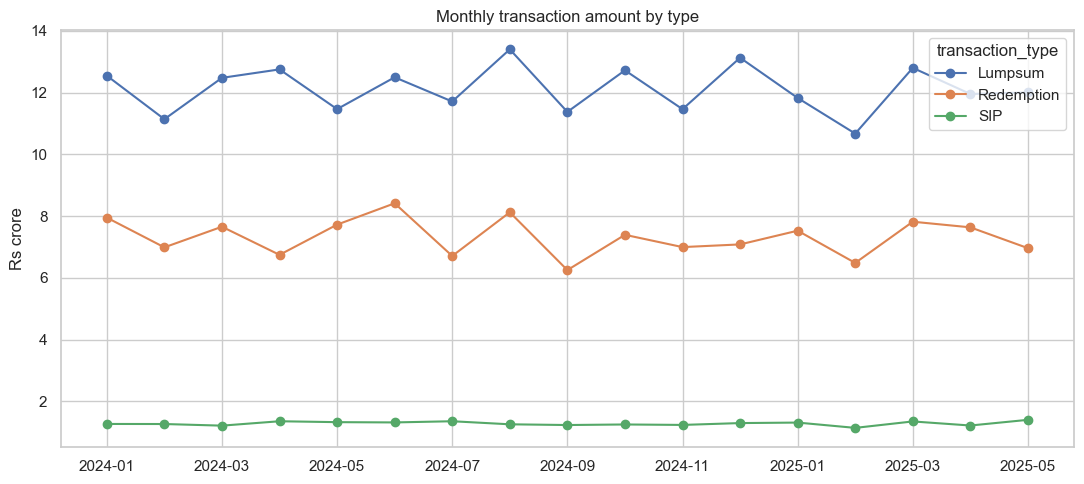

In [104]:
monthly = df8.pivot_table(index="month", columns="transaction_type", values="amount_inr", aggfunc="sum").fillna(0) / CR

ax = monthly.plot(marker="o", figsize=(11, 5))
ax.set_title("Monthly transaction amount by type")
ax.set_ylabel("Rs crore")
ax.set_xlabel("")
plt.tight_layout()
plt.show()

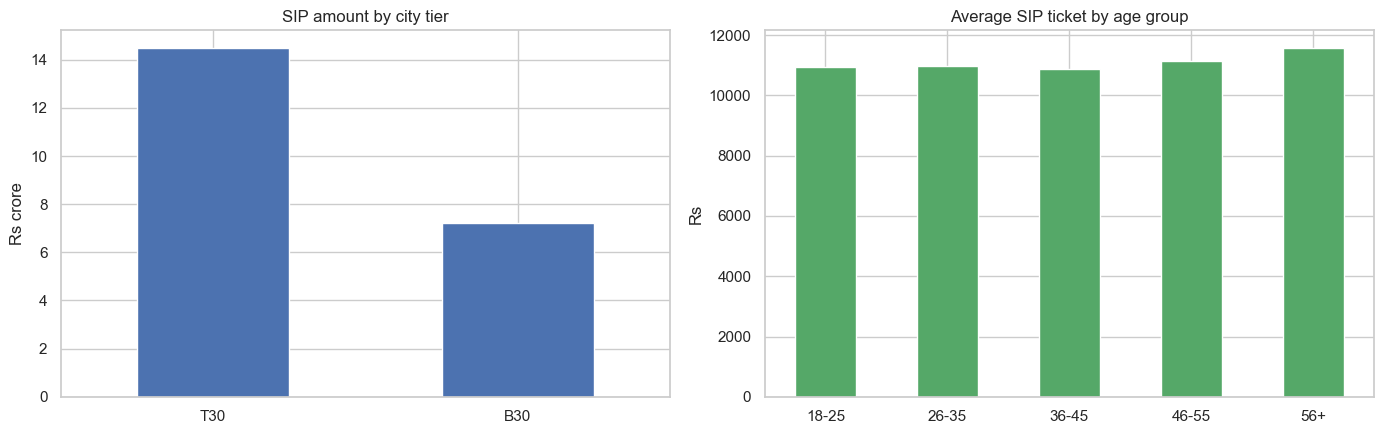

In [105]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

(sip_tx.groupby("city_tier")["amount_inr"].sum() / CR).sort_values(ascending=False).plot.bar(ax=axes[0], color="#4C72B0")
axes[0].set_title("SIP amount by city tier")
axes[0].set_ylabel("Rs crore")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=0)

sip_tx.groupby("age_group")["amount_inr"].mean().plot.bar(ax=axes[1], color="#55A868")
axes[1].set_title("Average SIP ticket by age group")
axes[1].set_ylabel("Rs")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

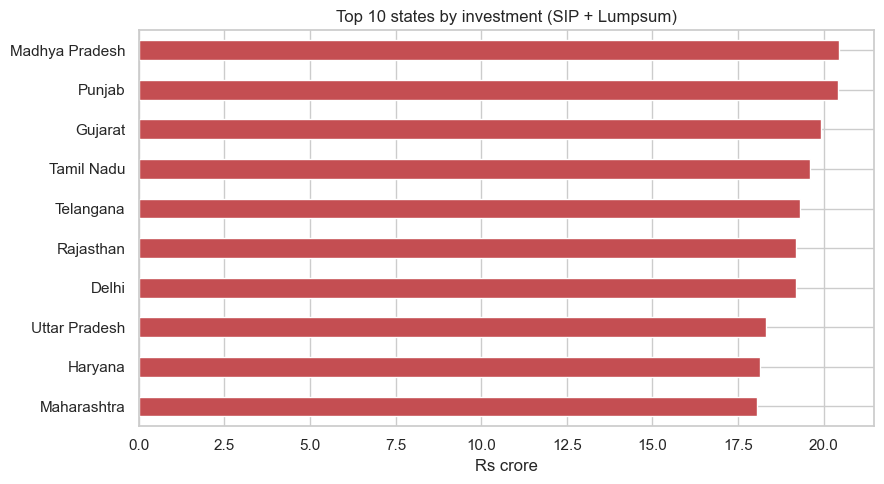

In [63]:
top_states = (invest.groupby("state")["amount_inr"].sum() / CR).nlargest(10).sort_values()

ax = top_states.plot.barh(figsize=(9, 5), color="#C44E52")
ax.set_title("Top 10 states by investment (SIP + Lumpsum)")
ax.set_xlabel("Rs crore")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

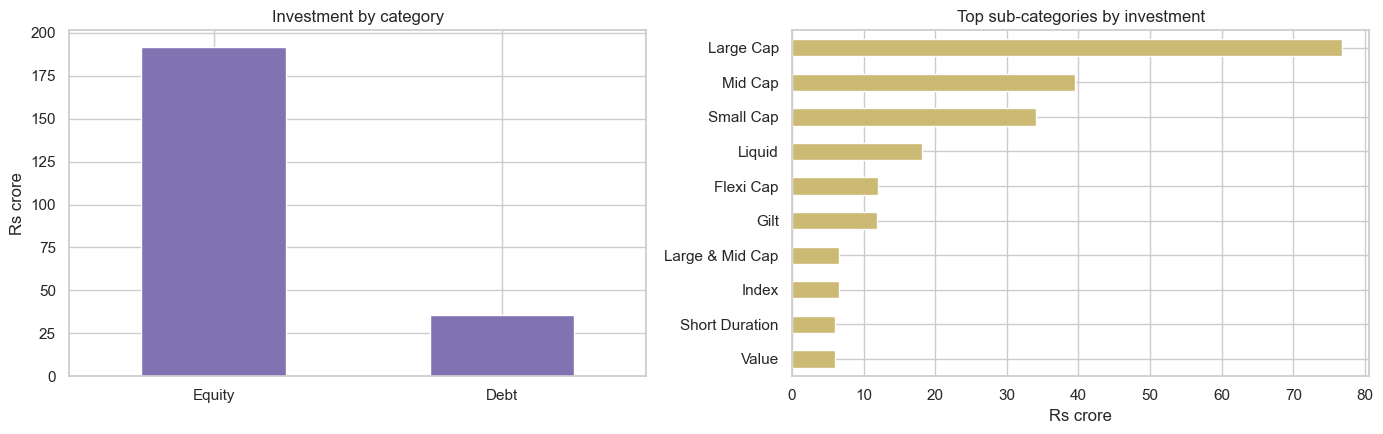

In [64]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

(invest.groupby("category")["amount_inr"].sum() / CR).sort_values(ascending=False).plot.bar(ax=axes[0], color="#8172B2")
axes[0].set_title("Investment by category")
axes[0].set_ylabel("Rs crore")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=0)

(invest.groupby("sub_category")["amount_inr"].sum() / CR).sort_values().tail(10).plot.barh(ax=axes[1], color="#CCB974")
axes[1].set_title("Top sub-categories by investment")
axes[1].set_xlabel("Rs crore")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

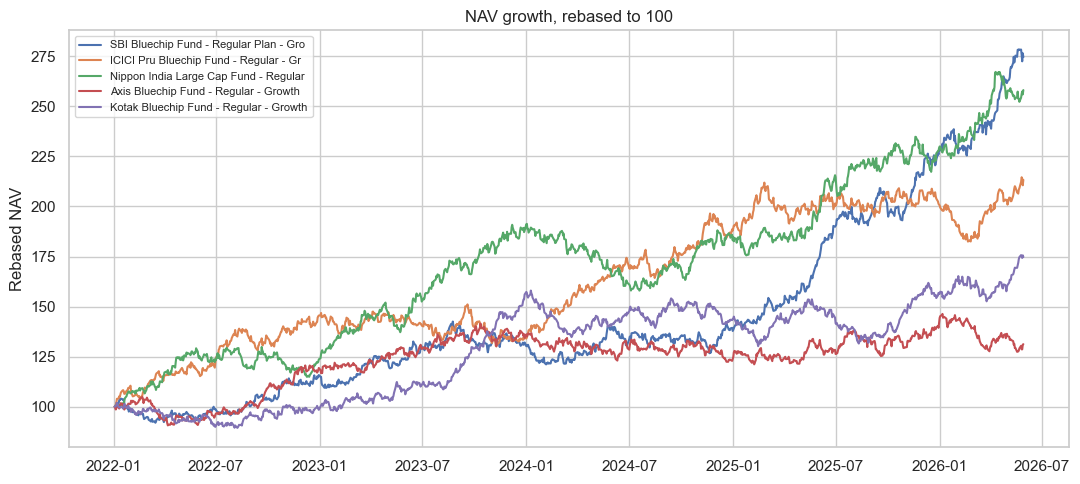

In [66]:
KEY_CODES = [119551, 120503, 118632, 119092, 120841]
nav = data["df2"].sort_values(["amfi_code", "date"])
codes = [c for c in KEY_CODES if c in set(nav["amfi_code"])] or df2["amfi_code"].value_counts().head(5).index.tolist()
names = df1.set_index("amfi_code")["scheme_name"].to_dict()

plt.figure(figsize=(11, 5))
for c in codes:
    s = df2[df2["amfi_code"] == c].set_index("date")["nav"]
    plt.plot(s.index, s / s.iloc[0] * 100, label=str(names.get(c, c))[:38])
plt.title("NAV growth, rebased to 100")
plt.ylabel("Rebased NAV")
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

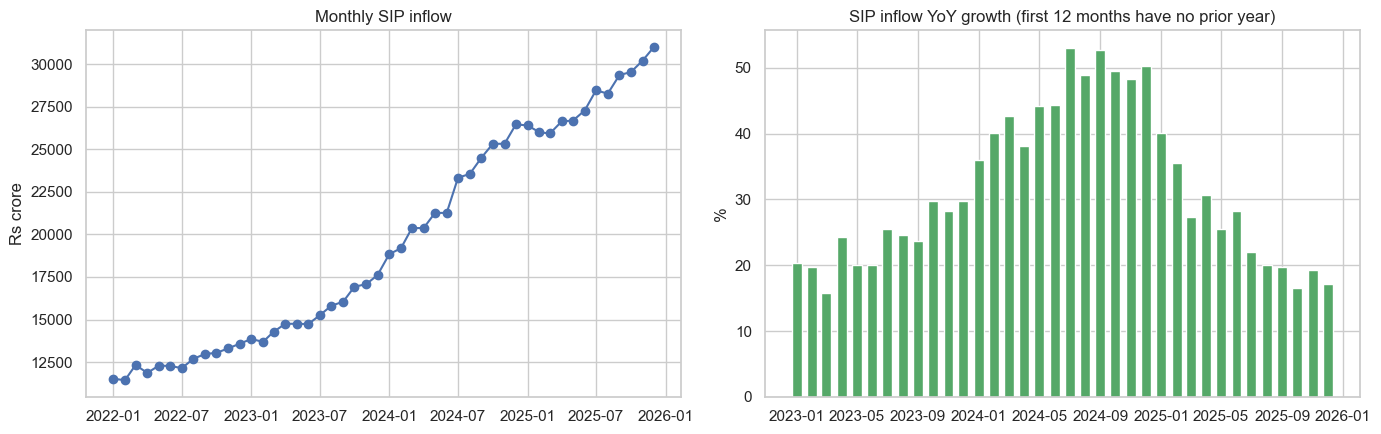

In [74]:
sip = data["df4"]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].plot(sip["month"],sip["sip_inflow_crore"], marker="o", color="#4C72B0")
axes[0].set_title("Monthly SIP inflow")
axes[0].set_ylabel("Rs crore")

axes[1].bar(sip["month"], sip["yoy_growth_pct"], width=20, color="#55A868")
axes[1].set_title("SIP inflow YoY growth (first 12 months have no prior year)")
axes[1].set_ylabel("%")

plt.tight_layout()
plt.show()

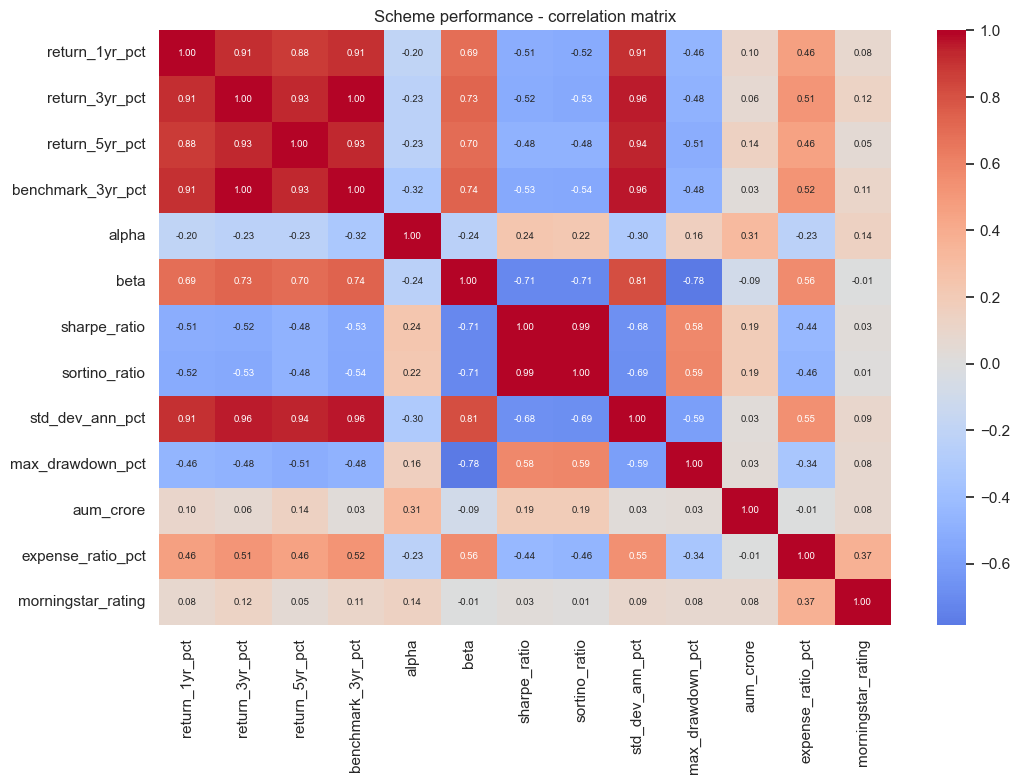

In [76]:
perf_num = data["df7"].select_dtypes(include="number").drop(columns=["amfi_code"], errors="ignore")

plt.figure(figsize=(11, 8))
sns.heatmap(perf_num.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 7})
plt.title("Scheme performance - correlation matrix")
plt.tight_layout()
plt.show()

In [77]:
amt = sip_tx["amount_inr"]
pd.Series(
    {
        "count": len(amt),
        "mean": amt.mean(),
        "median": amt.median(),
        "mode": amt.mode().iloc[0],
        "std dev": amt.std(),
        "skewness": amt.skew(),
        "min": amt.min(),
        "max": amt.max(),
    },
    name="SIP amount (Rs)",
).to_frame()

,SIP amount (Rs)
count,"19,716.00"
mean,"11,018.13"
median,"5,139.00"
mode,579.00
std dev,"14,218.20"
skewness,1.92
min,400.00
max,"59,998.00"


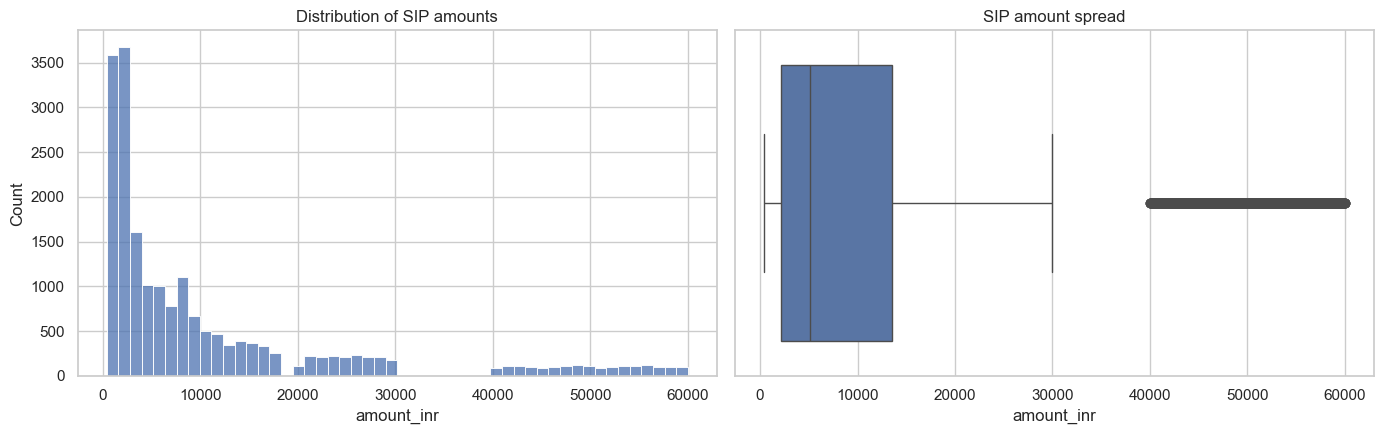

In [78]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(amt, bins=50, ax=axes[0])
axes[0].set_title("Distribution of SIP amounts")
sns.boxplot(x=amt, ax=axes[1])
axes[1].set_title("SIP amount spread")
plt.tight_layout()
plt.show()

Correlation (r)  : 0.003
R-squared        : 0.000
Slope            : Rs 2.03 more SIP per extra lakh of annual income
p-value          : 0.6730


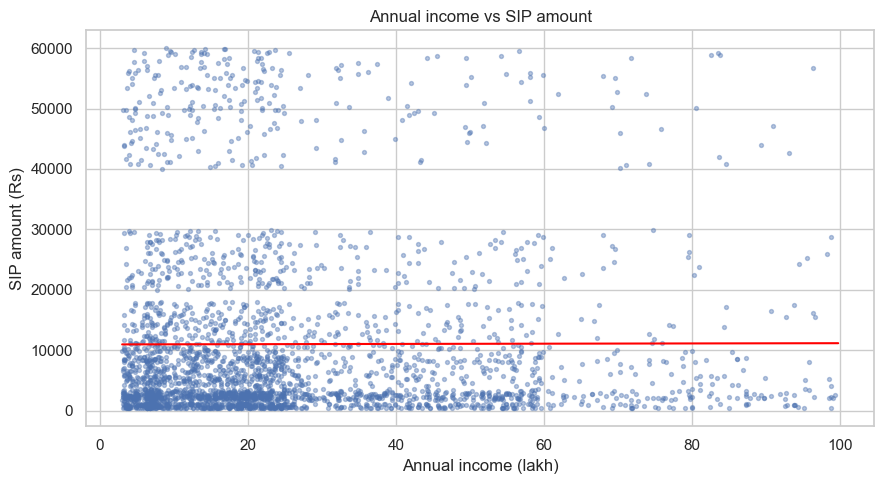

In [79]:
reg = sip_tx[["annual_income_lakh", "amount_inr"]].dropna()
res = stats.linregress(reg["annual_income_lakh"], reg["amount_inr"])

print(f"Correlation (r)  : {res.rvalue:.3f}")
print(f"R-squared        : {res.rvalue ** 2:.3f}")
print(f"Slope            : Rs {res.slope:,.2f} more SIP per extra lakh of annual income")
print(f"p-value          : {res.pvalue:.4f}")

sample = reg.sample(min(3000, len(reg)), random_state=42)
plt.figure(figsize=(9, 5))
plt.scatter(sample["annual_income_lakh"], sample["amount_inr"], s=8, alpha=0.4)
xs = np.array([reg["annual_income_lakh"].min(), reg["annual_income_lakh"].max()])
plt.plot(xs, res.intercept + res.slope * xs, color="red")
plt.title("Annual income vs SIP amount")
plt.xlabel("Annual income (lakh)")
plt.ylabel("SIP amount (Rs)")
plt.tight_layout()
plt.show()

In [84]:
print("df8 columns:", df8.columns.tolist())
print("df7 columns:", data["df7"].columns.tolist())
print("Available datasets:", list(data.keys()))

df8 columns: ['investor_id', 'transaction_date', 'amfi_code', 'transaction_type', 'amount_inr', 'state', 'city', 'city_tier', 'age_group', 'gender', 'annual_income_lakh', 'payment_mode', 'kyc_status', 'is_amount_outlier', 'scheme_name_x', 'fund_house_x', 'category_x', 'sub_category_x', 'plan_x', 'scheme_name_y', 'fund_house_y', 'category_y', 'sub_category_y', 'plan_y', 'scheme_name', 'fund_house', 'category', 'sub_category', 'plan', 'month']
df7 columns: ['amfi_code', 'scheme_name', 'fund_house', 'category', 'plan', 'return_1yr_pct', 'return_3yr_pct', 'return_5yr_pct', 'benchmark_3yr_pct', 'alpha', 'beta', 'sharpe_ratio', 'sortino_ratio', 'std_dev_ann_pct', 'max_drawdown_pct', 'aum_crore', 'expense_ratio_pct', 'morningstar_rating', 'risk_grade']
Available datasets: ['df1', 'df2', 'df3', 'df4', 'df5', 'df6', 'df7', 'df8', 'df9', 'df10']


In [85]:

# Monthly net investment
net_by_month = (
    df8.assign(
        signed=np.where(
            df8["transaction_type"].str.strip().str.lower() == "redemption",
            -df8["amount_inr"],
            df8["amount_inr"]
        )
    )
    .groupby("month")["signed"]
    .sum()
)

# SIP share by city tier
tier_share = (
    sip_tx.groupby("city_tier")["amount_inr"].sum()
    / sip_tx["amount_inr"].sum() * 100
)

# Mutual fund performance data
perf = data["df7"]

# Format month labels safely
peak_month = pd.to_datetime(net_by_month.idxmax())
lowest_month = pd.to_datetime(net_by_month.idxmin())

insights = [
    f"Total investments (SIP + Lumpsum) are Rs {inflow / CR:,.0f} crore against Rs {outflow / CR:,.0f} crore of redemptions, so net investment is Rs {net / CR:,.0f} crore.",

    f"SIP is {(df8['transaction_type'].str.strip().str.lower() == 'sip').mean() * 100:.0f}% of all transactions, with an average ticket of Rs {sip_tx['amount_inr'].mean():,.0f}.",

    f"The top state by investment is {invest.groupby('state')['amount_inr'].sum().idxmax()}, and the top category is {invest.groupby('category')['amount_inr'].sum().idxmax()}.",

    "SIP share by city tier: " + ", ".join(
        f"{k} {v:.0f}%" for k, v in tier_share.items()
    ) + ".",

    f"The age group with the highest average SIP ticket is {sip_tx.groupby('age_group')['amount_inr'].mean().idxmax()}.",

    f"Net investment peaked in {peak_month.strftime('%b %Y')} and was lowest in {lowest_month.strftime('%b %Y')}.",

    f"Best 3-year return: {perf.loc[perf['return_3yr_pct'].idxmax(), 'scheme_name']} ({perf['return_3yr_pct'].max():.1f}%). Best Sharpe ratio: {perf.loc[perf['sharpe_ratio'].idxmax(), 'scheme_name']} ({perf['sharpe_ratio'].max():.2f}).",

    f"Industry monthly SIP inflow went from Rs {sip['sip_inflow_crore'].iloc[0]:,.0f} crore to Rs {sip['sip_inflow_crore'].iloc[-1]:,.0f} crore.",

    f"Income vs SIP amount: correlation r = {res.rvalue:.2f}, so income explains {res.rvalue ** 2 * 100:.1f}% of the variation in SIP amount."
]

for line in insights:
    print("-", line)


- Total investments (SIP + Lumpsum) are Rs 228 crore against Rs 124 crore of redemptions, so net investment is Rs 103 crore.
- SIP is 60% of all transactions, with an average ticket of Rs 11,018.
- The top state by investment is Madhya Pradesh, and the top category is Equity.
- SIP share by city tier: B30 33%, T30 67%.
- The age group with the highest average SIP ticket is 56+.
- Net investment peaked in Apr 2024 and was lowest in May 2024.
- Best 3-year return: SBI Small Cap Fund - Regular Plan - Growth (23.4%). Best Sharpe ratio: ICICI Pru Liquid Fund - Regular - Growth (7.68).
- Industry monthly SIP inflow went from Rs 11,517 crore to Rs 31,002 crore.
- Income vs SIP amount: correlation r = 0.00, so income explains 0.0% of the variation in SIP amount.


In [89]:
OUTPUT_NAMES = {
    "df1": "fund_master",
    "df2": "nav_history",
    "df3": "aum_by_fund_house",
    "df4": "monthly_sip_inflows",
    "df5": "category_inflows",
    "df6": "industry_folio_count",
    "df7": "scheme_performance",
    "df8": "investor_transactions",
    "df9": "portfolio_holdings",
    "df10": "benchmark_indices",
}

for key, fname in OUTPUT_NAMES.items():
    data[key].to_csv(OUT_DIR / f"{fname}_clean.csv", index=False)

pd.DataFrame(cleaning_log).to_csv(OUT_DIR / "cleaning_log.csv", index=False)
pd.DataFrame(checks).to_csv(OUT_DIR / "validation_checks.csv", index=False)

print(f"Saved to {OUT_DIR.resolve()}:")
for f in sorted(OUT_DIR.glob("*.csv")):
    print(f"  {f.name:<38} {f.stat().st_size / 1024:>9,.0f} KB")

Saved to C:\Users\Sakshi Mane\processed:
  aum_by_fund_house_clean.csv                    4 KB
  benchmark_indices_clean.csv                  253 KB
  category_inflows_clean.csv                     4 KB
  cleaning_log.csv                               2 KB
  fund_master_clean.csv                          7 KB
  industry_folio_count_clean.csv                 1 KB
  investor_transactions_clean.csv            3,278 KB
  monthly_sip_inflows_clean.csv                  2 KB
  nav_history_clean.csv                      1,236 KB
  portfolio_holdings_clean.csv                  24 KB
  scheme_performance_clean.csv                   7 KB
  validation_checks.csv                          0 KB


In [90]:
pd.DataFrame(cleaning_log)

,dataset,action,affected
0,df1,standardised fund_house names ('MF' -> 'Mutual...,20
1,df3,standardised fund_house names ('MF' -> 'Mutual...,45
2,df7,standardised fund_house names ('MF' -> 'Mutual...,20
3,df1,standardised fund_house names ('MF' -> 'Mutual...,0
4,df3,standardised fund_house names ('MF' -> 'Mutual...,0
5,df7,standardised fund_house names ('MF' -> 'Mutual...,0
6,df1,converted 'launch_date' to datetime (unparseab...,40
7,df2,converted 'date' to datetime (unparseable: 0),46000
8,df3,converted 'date' to datetime (unparseable: 0),90
9,df8,converted 'transaction_date' to datetime (unpa...,32778
